<a href="https://colab.research.google.com/github/SAMBOAH95/Machine-Learning-Projects/blob/main/Level-2-Task-4-Loan-Approval-Prediction/Loan_Approval_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install required libraries

!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Display settings
pd.set_option('display.max_columns', None)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Dataset download URL
url = "https://raw.githubusercontent.com/shrikant-temburwar/Loan-Prediction-Dataset/master/train.csv"

# Load dataset
df = pd.read_csv(url)

# Save dataset to Google Drive
dataset_path = "/content/drive/MyDrive/Elevo/Level2/Task4/Loan_Approval_Dataset.csv"

df.to_csv(dataset_path, index=False)

print("Dataset downloaded and saved successfully!")
print("Dataset shape:", df.shape)
print("Saved location:", dataset_path)

df.head()

Dataset downloaded and saved successfully!
Dataset shape: (614, 13)
Saved location: /content/drive/MyDrive/Elevo/Level2/Task4/Loan_Approval_Dataset.csv


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
# Inspect dataset structure

print("Dataset Information")
print("===================")

df.info()

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
# Calculate missing values

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})

# Display only columns with missing values
missing_summary = missing_summary[missing_summary['Missing Values'] > 0]

print("Missing Values Summary")
print("=======================")

display(missing_summary.sort_values(
    by='Missing Values',
    ascending=False
))

Missing Values Summary


,Missing Values,Percentage (%)
Credit_History,50,8.143322
Self_Employed,32,5.211726
LoanAmount,22,3.583062
Dependents,15,2.442997
Loan_Amount_Term,14,2.280130
Gender,13,2.117264
Married,3,0.488599


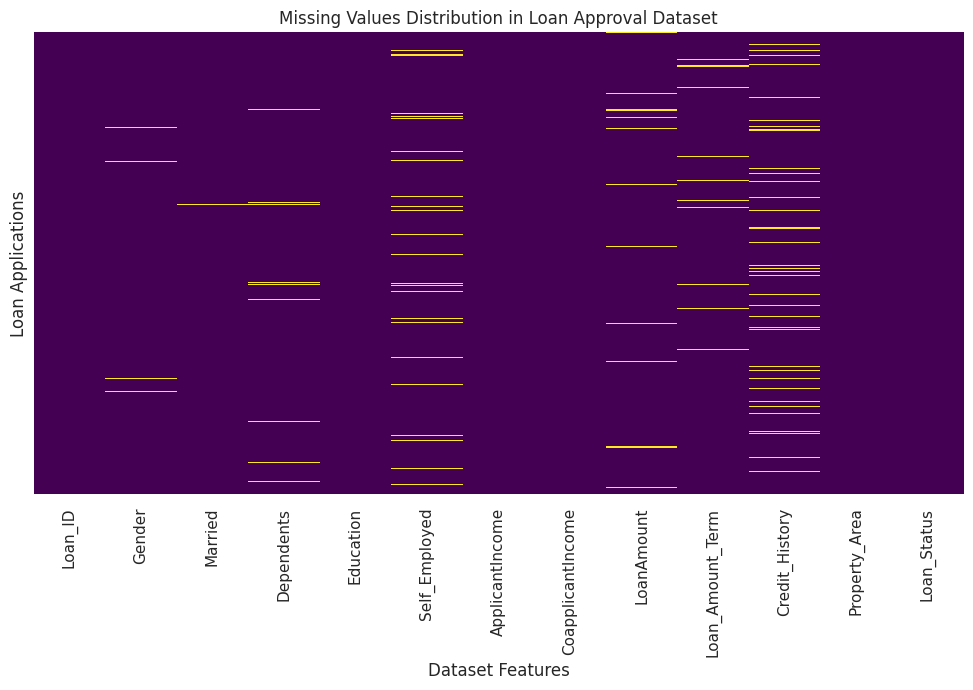

In [7]:
# Visualise missing values

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Distribution in Loan Approval Dataset")
plt.xlabel("Dataset Features")
plt.ylabel("Loan Applications")

plt.show()

Loan Status Distribution
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Percentage Distribution
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


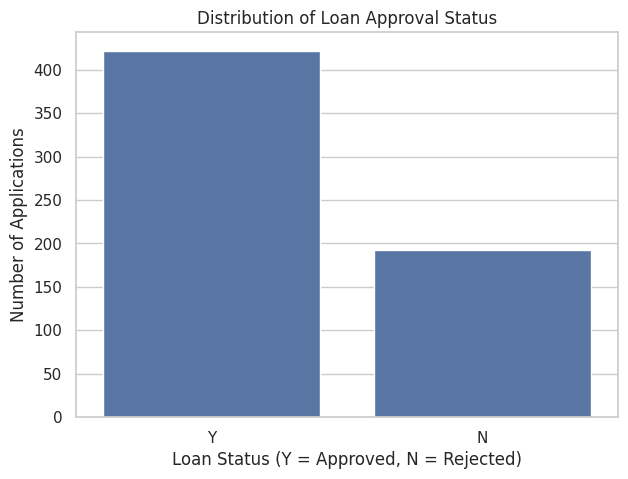

In [8]:
# Analyse loan approval distribution

print("Loan Status Distribution")
print("=========================")

print(df['Loan_Status'].value_counts())

print("\nPercentage Distribution")
print("=======================")

print(
    df['Loan_Status'].value_counts(normalize=True).mul(100).round(2)
)

# Visualise target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Loan_Status'
)

plt.title("Distribution of Loan Approval Status")
plt.xlabel("Loan Status (Y = Approved, N = Rejected)")
plt.ylabel("Number of Applications")

plt.show()

In [9]:
# Statistical summary of numerical features

numerical_features = df.select_dtypes(include=['int64', 'float64'])

print("Numerical Features")
print("==================")

display(numerical_features.describe())

Numerical Features


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


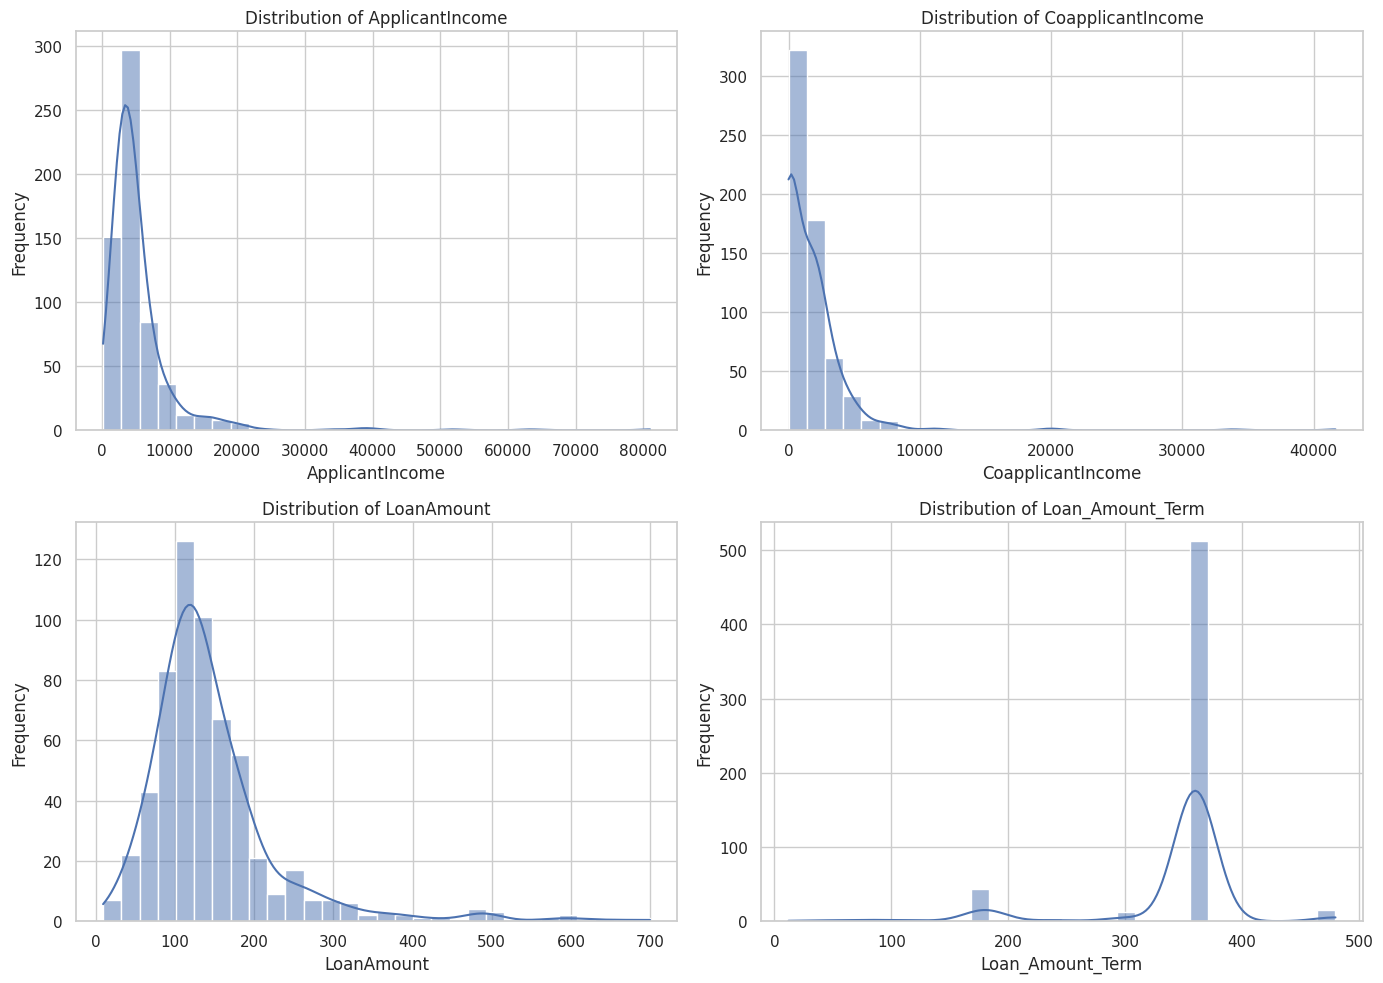

In [10]:
# Visualise distributions of continuous numerical features

continuous_features = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

plt.figure(figsize=(14, 10))

for i, column in enumerate(continuous_features, 1):
    plt.subplot(2, 2, i)

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [11]:
# Identify categorical features

categorical_features = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical Features")
print("====================")

print(categorical_features)

# Display unique values and their frequencies
for column in categorical_features:
    print(f"\n{column}")
    print("--------------------")
    print(df[column].value_counts(dropna=False))

Categorical Features
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status']

Loan_ID
--------------------
Loan_ID
LP001002    1
LP001003    1
LP001005    1
LP001006    1
LP001008    1
           ..
LP002978    1
LP002979    1
LP002983    1
LP002984    1
LP002990    1
Name: count, Length: 614, dtype: int64

Gender
--------------------
Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64

Married
--------------------
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64

Dependents
--------------------
Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64

Education
--------------------
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

Self_Employed
--------------------
Self_Employed
No     500
Yes     82
NaN     32
Name: count, dtype: int64

Property_Area
--------------------
Property_Area
Semiurban    233
Urban        202
Rural       

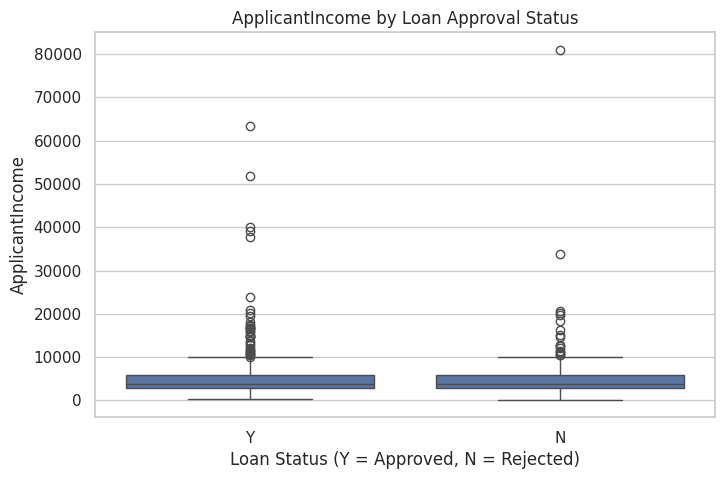

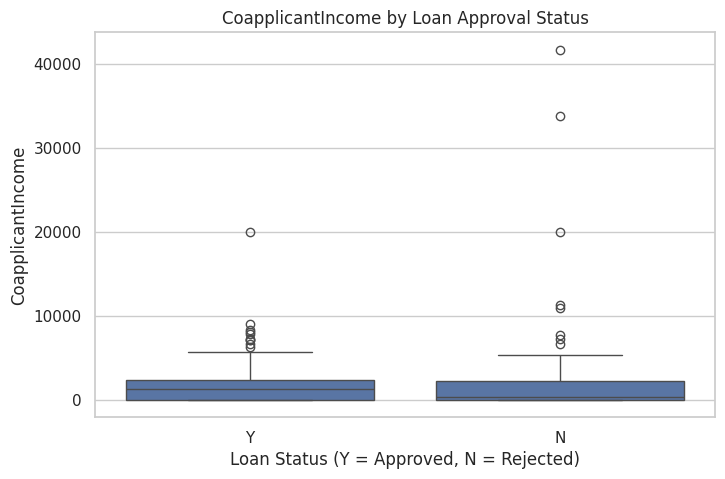

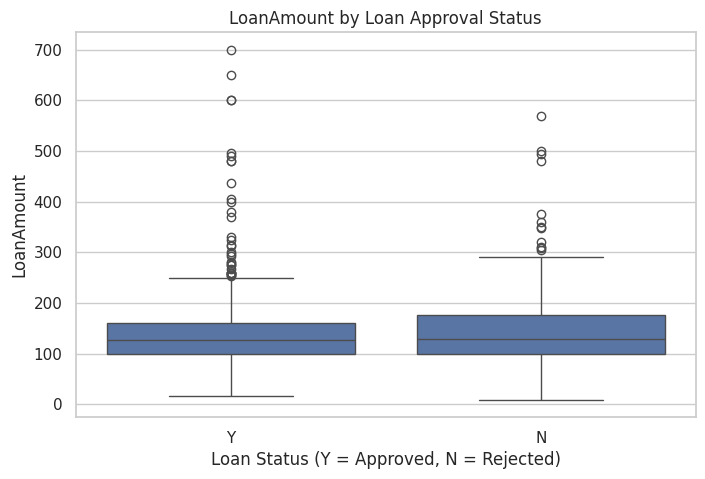

In [12]:
# Compare numerical features by loan status

features = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount'
]

for column in features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x='Loan_Status',
        y=column
    )

    plt.title(f'{column} by Loan Approval Status')
    plt.xlabel('Loan Status (Y = Approved, N = Rejected)')
    plt.ylabel(column)

    plt.show()

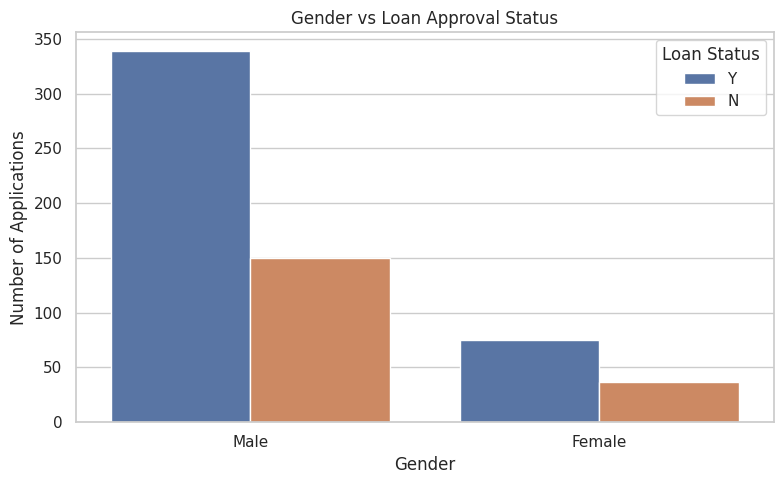

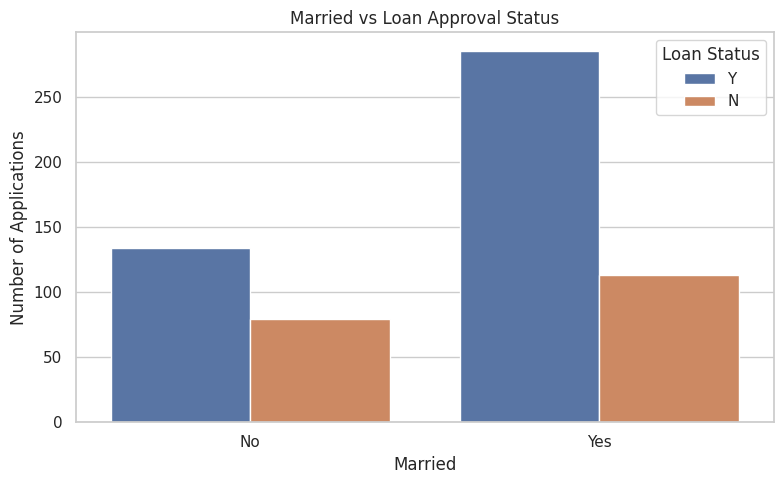

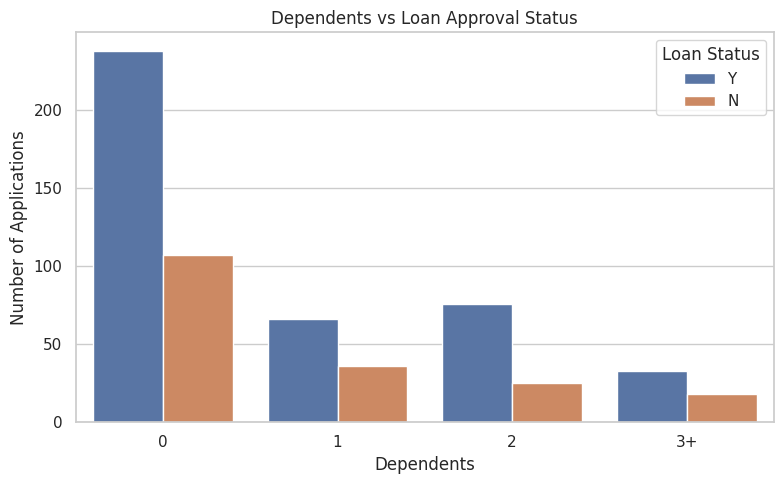

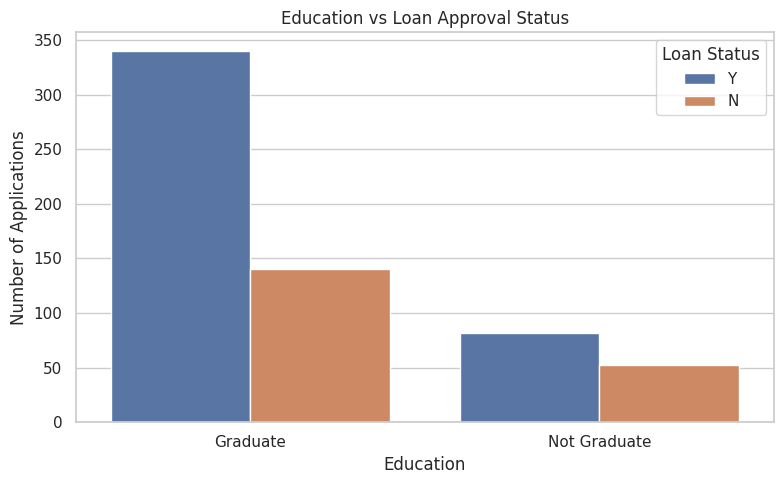

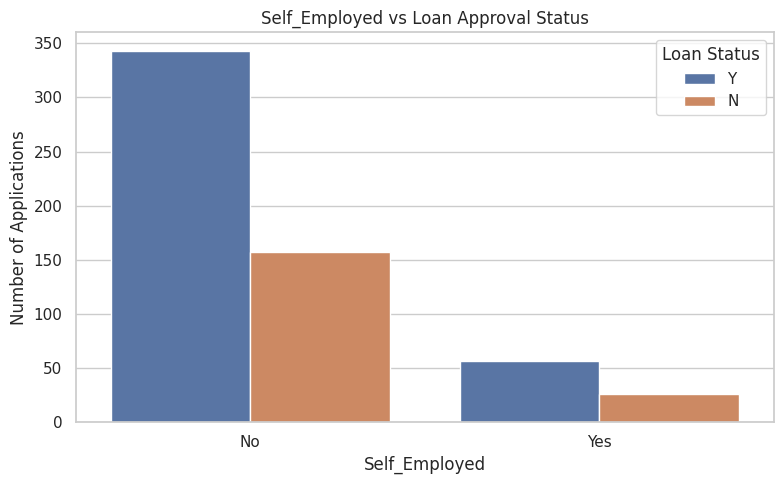

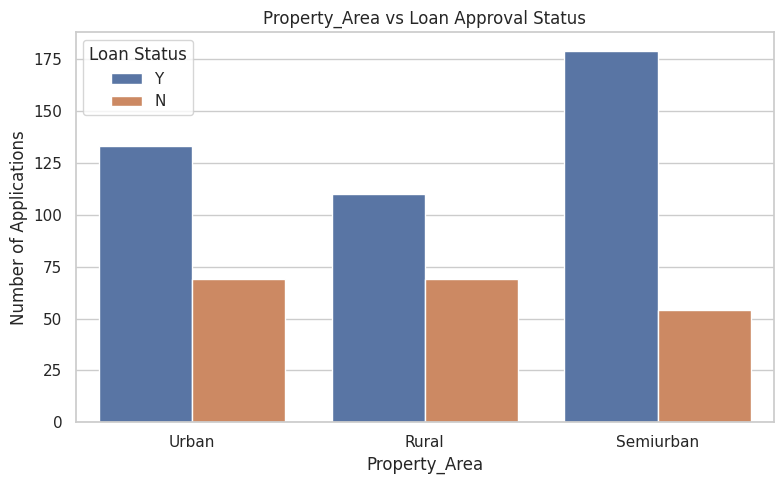

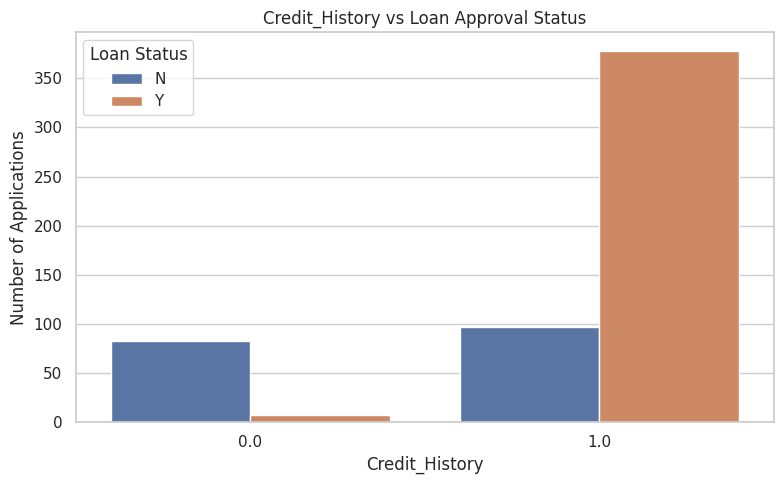

In [13]:
# Analyse categorical features against loan approval

categorical_features = [
    'Gender',
    'Married',
    'Dependents',
    'Education',
    'Self_Employed',
    'Property_Area',
    'Credit_History'
]

for column in categorical_features:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=column,
        hue='Loan_Status'
    )

    plt.title(f'{column} vs Loan Approval Status')
    plt.xlabel(column)
    plt.ylabel('Number of Applications')
    plt.legend(title='Loan Status')

    plt.tight_layout()
    plt.show()

In [14]:
# Separate independent variables (X) and target variable (y)

# Remove Loan_ID and Loan_Status from the feature set
X = df.drop(columns=['Loan_ID', 'Loan_Status'])

# Select Loan_Status as the target
y = df['Loan_Status']

# Display the results
print("Feature and Target Separation")
print("=============================")

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature and Target Separation
Features (X) shape: (614, 11)
Target (y) shape: (614,)

Feature columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Target distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [15]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training and Testing Data")
print("=========================")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check class distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training and Testing Data
X_train: (491, 11)
X_test: (123, 11)
y_train: (491,)
y_test: (123,)

Training Target Distribution:
Loan_Status
Y    337
N    154
Name: count, dtype: int64

Testing Target Distribution:
Loan_Status
Y    85
N    38
Name: count, dtype: int64


In [16]:
# Identify numerical and categorical features

numerical_features = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

categorical_features = [
    'Gender',
    'Married',
    'Dependents',
    'Education',
    'Self_Employed',
    'Credit_History',
    'Property_Area'
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))

Numerical Features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

Categorical Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']

Total numerical features: 4
Total categorical features: 7
Total features: 11


In [17]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing pipeline
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
# Fit preprocessing pipeline on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted pipeline
X_test_processed = preprocessor.transform(X_test)

# Display processed dataset information
print("Preprocessing completed successfully!")
print("--------------------------------------")

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

print("\nRemaining missing values in training data:",
      np.isnan(X_train_processed.toarray()).sum()
      if hasattr(X_train_processed, "toarray")
      else np.isnan(X_train_processed).sum())

print("Remaining missing values in testing data:",
      np.isnan(X_test_processed.toarray()).sum()
      if hasattr(X_test_processed, "toarray")
      else np.isnan(X_test_processed).sum())

Preprocessing completed successfully!
--------------------------------------
Processed training data shape: (491, 21)
Processed testing data shape: (123, 21)

Remaining missing values in training data: 0
Remaining missing values in testing data: 0


In [19]:
# Train Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Fit model using training data
logistic_model.fit(X_train_processed, y_train)

# Make predictions on testing data
y_pred_logistic = logistic_model.predict(X_test_processed)

print("Logistic Regression trained successfully!")
print("Number of predictions:", len(y_pred_logistic))
print("\nFirst 10 predictions:")
print(y_pred_logistic[:10])

Logistic Regression trained successfully!
Number of predictions: 123

First 10 predictions:
['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']


In [20]:
# Evaluate Logistic Regression

print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("===========================================")

print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=['Rejected (N)', 'Approved (Y)']
))

# Calculate individual metrics
print("\nOverall Performance Metrics")
print("===========================")

print("Accuracy:", round(accuracy_score(y_test, y_pred_logistic), 4))

print("Precision (Macro):", round(
    precision_score(y_test, y_pred_logistic, average='macro'), 4
))

print("Recall (Macro):", round(
    recall_score(y_test, y_pred_logistic, average='macro'), 4
))

print("F1-Score (Macro):", round(
    f1_score(y_test, y_pred_logistic, average='macro'), 4
))

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

Rejected (N)       0.96      0.58      0.72        38
Approved (Y)       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


Overall Performance Metrics
Accuracy: 0.8618
Precision (Macro): 0.8983
Recall (Macro): 0.7836
F1-Score (Macro): 0.8147


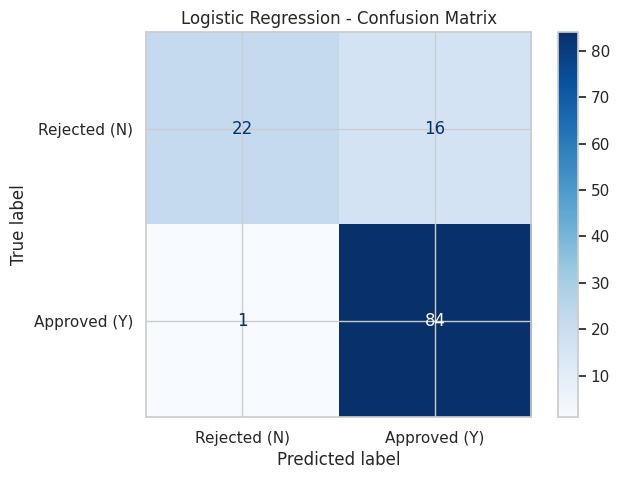

In [21]:
# Confusion matrix for Logistic Regression

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=['N', 'Y']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=['Rejected (N)', 'Approved (Y)']
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap='Blues',
    ax=ax,
    values_format='d'
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [22]:
# Train Decision Tree Classifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

# Fit model
decision_tree_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_tree = decision_tree_model.predict(X_test_processed)

print("Decision Tree trained successfully!")
print("Number of predictions:", len(y_pred_tree))

print("\nFirst 10 predictions:")
print(y_pred_tree[:10])

Decision Tree trained successfully!
Number of predictions: 123

First 10 predictions:
['N' 'N' 'Y' 'Y' 'Y' 'N' 'Y' 'Y' 'N' 'Y']


In [23]:
# Evaluate Decision Tree

print("DECISION TREE - CLASSIFICATION REPORT")
print("=====================================")

print(classification_report(
    y_test,
    y_pred_tree,
    target_names=['Rejected (N)', 'Approved (Y)']
))

# Calculate performance metrics
print("\nOverall Performance Metrics")
print("===========================")

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_tree), 4
))

print("Precision (Macro):", round(
    precision_score(y_test, y_pred_tree, average='macro'), 4
))

print("Recall (Macro):", round(
    recall_score(y_test, y_pred_tree, average='macro'), 4
))

print("F1-Score (Macro):", round(
    f1_score(y_test, y_pred_tree, average='macro'), 4
))

DECISION TREE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

Rejected (N)       0.64      0.71      0.68        38
Approved (Y)       0.86      0.82      0.84        85

    accuracy                           0.79       123
   macro avg       0.75      0.77      0.76       123
weighted avg       0.80      0.79      0.79       123


Overall Performance Metrics
Accuracy: 0.7886
Precision (Macro): 0.7535
Recall (Macro): 0.767
F1-Score (Macro): 0.7592


In [24]:
# Train Random Forest Classifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Fit model
random_forest_model.fit(X_train_processed, y_train)

# Make predictions
y_pred_rf = random_forest_model.predict(X_test_processed)

print("Random Forest trained successfully!")
print("Number of predictions:", len(y_pred_rf))

print("\nFirst 10 predictions:")
print(y_pred_rf[:10])

Random Forest trained successfully!
Number of predictions: 123

First 10 predictions:
['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'N' 'Y']


In [25]:
# Evaluate Random Forest

print("RANDOM FOREST - CLASSIFICATION REPORT")
print("=====================================")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Rejected (N)', 'Approved (Y)']
))

# Calculate performance metrics
print("\nOverall Performance Metrics")
print("===========================")

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_rf), 4
))

print("Precision (Macro):", round(
    precision_score(y_test, y_pred_rf, average='macro'), 4
))

print("Recall (Macro):", round(
    recall_score(y_test, y_pred_rf, average='macro'), 4
))

print("F1-Score (Macro):", round(
    f1_score(y_test, y_pred_rf, average='macro'), 4
))

RANDOM FOREST - CLASSIFICATION REPORT
              precision    recall  f1-score   support

Rejected (N)       0.79      0.61      0.69        38
Approved (Y)       0.84      0.93      0.88        85

    accuracy                           0.83       123
   macro avg       0.82      0.77      0.78       123
weighted avg       0.83      0.83      0.82       123


Overall Performance Metrics
Accuracy: 0.8293
Precision (Macro): 0.8168
Recall (Macro): 0.7673
F1-Score (Macro): 0.7846


In [26]:
# Compare classification models

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Macro Precision': [
        precision_score(y_test, y_pred_logistic, average='macro'),
        precision_score(y_test, y_pred_tree, average='macro'),
        precision_score(y_test, y_pred_rf, average='macro')
    ],
    'Macro Recall': [
        recall_score(y_test, y_pred_logistic, average='macro'),
        recall_score(y_test, y_pred_tree, average='macro'),
        recall_score(y_test, y_pred_rf, average='macro')
    ],
    'Macro F1-Score': [
        f1_score(y_test, y_pred_logistic, average='macro'),
        f1_score(y_test, y_pred_tree, average='macro'),
        f1_score(y_test, y_pred_rf, average='macro')
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("============================")

display(model_comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.8618,0.8983,0.7836,0.8147
1,Decision Tree,0.7886,0.7535,0.7670,0.7592
2,Random Forest,0.8293,0.8168,0.7673,0.7846


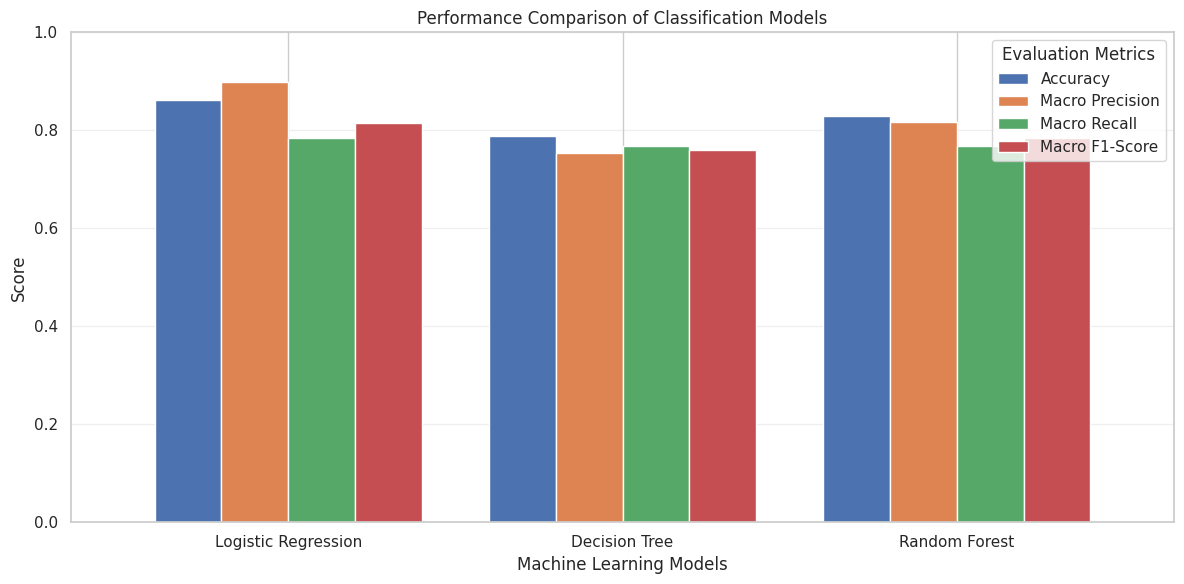

In [27]:
# Visualise model performance comparison

metrics = [
    'Accuracy',
    'Macro Precision',
    'Macro Recall',
    'Macro F1-Score'
]

model_comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Performance Comparison of Classification Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Train class-weighted Logistic Regression

balanced_logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Fit model
balanced_logistic_model.fit(X_train_processed, y_train)

# Generate predictions
y_pred_balanced_logistic = balanced_logistic_model.predict(
    X_test_processed
)

print("Balanced Logistic Regression trained successfully!")
print("Number of predictions:", len(y_pred_balanced_logistic))

Balanced Logistic Regression trained successfully!
Number of predictions: 123


In [29]:
# Evaluate Balanced Logistic Regression

print("BALANCED LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("===================================================")

print(classification_report(
    y_test,
    y_pred_balanced_logistic,
    target_names=['Rejected (N)', 'Approved (Y)']
))

print("\nOverall Performance Metrics")
print("===========================")

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced_logistic), 4
))

print("Macro Precision:", round(
    precision_score(y_test, y_pred_balanced_logistic, average='macro'), 4
))

print("Macro Recall:", round(
    recall_score(y_test, y_pred_balanced_logistic, average='macro'), 4
))

print("Macro F1-Score:", round(
    f1_score(y_test, y_pred_balanced_logistic, average='macro'), 4
))

BALANCED LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

Rejected (N)       0.73      0.71      0.72        38
Approved (Y)       0.87      0.88      0.88        85

    accuracy                           0.83       123
   macro avg       0.80      0.80      0.80       123
weighted avg       0.83      0.83      0.83       123


Overall Performance Metrics
Accuracy: 0.8293
Macro Precision: 0.8009
Macro Recall: 0.7964
Macro F1-Score: 0.7986


In [30]:
# Updated comparison of all four models

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_balanced_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Macro Precision': [
        precision_score(y_test, y_pred_logistic, average='macro'),
        precision_score(y_test, y_pred_balanced_logistic, average='macro'),
        precision_score(y_test, y_pred_tree, average='macro'),
        precision_score(y_test, y_pred_rf, average='macro')
    ],
    'Macro Recall': [
        recall_score(y_test, y_pred_logistic, average='macro'),
        recall_score(y_test, y_pred_balanced_logistic, average='macro'),
        recall_score(y_test, y_pred_tree, average='macro'),
        recall_score(y_test, y_pred_rf, average='macro')
    ],
    'Macro F1-Score': [
        f1_score(y_test, y_pred_logistic, average='macro'),
        f1_score(y_test, y_pred_balanced_logistic, average='macro'),
        f1_score(y_test, y_pred_tree, average='macro'),
        f1_score(y_test, y_pred_rf, average='macro')
    ]
})

print("UPDATED MODEL PERFORMANCE COMPARISON")
print("====================================")

display(model_comparison.round(4))

UPDATED MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.8618,0.8983,0.7836,0.8147
1,Balanced Logistic Regression,0.8293,0.8009,0.7964,0.7986
2,Decision Tree,0.7886,0.7535,0.7670,0.7592
3,Random Forest,0.8293,0.8168,0.7673,0.7846


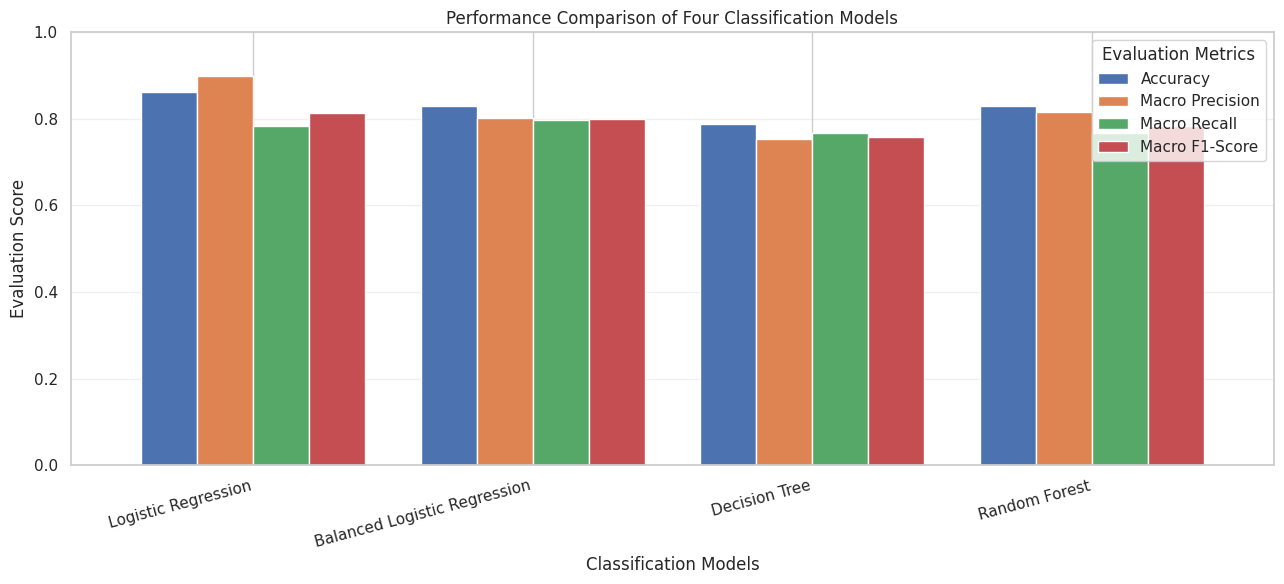

In [31]:
# Visualise updated model comparison

metrics = [
    'Accuracy',
    'Macro Precision',
    'Macro Recall',
    'Macro F1-Score'
]

model_comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(13, 6),
    width=0.8
)

plt.title('Performance Comparison of Four Classification Models')
plt.xlabel('Classification Models')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

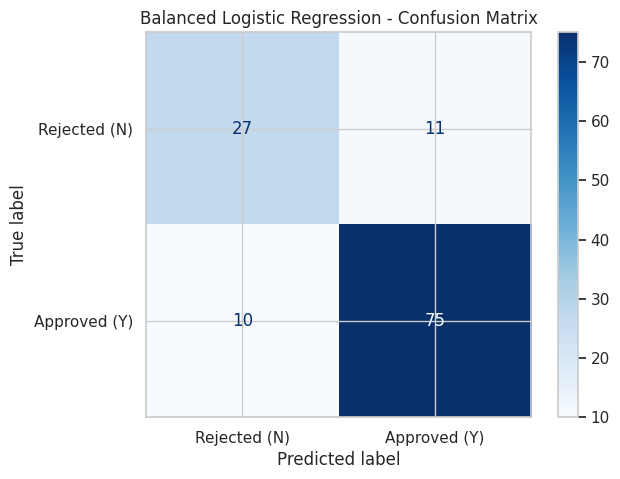

In [32]:
# Confusion matrix for Balanced Logistic Regression

cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced_logistic,
    labels=['N', 'Y']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=['Rejected (N)', 'Approved (Y)']
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap='Blues',
    ax=ax,
    values_format='d'
)

plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

In [33]:
# Import GridSearchCV
from sklearn.model_selection import GridSearchCV

# Create Logistic Regression pipeline
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

# Define hyperparameter grid
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['lbfgs', 'liblinear']
}

# Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

# Train and search for best parameters
grid_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")
print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation Macro F1-score:")
print(round(grid_search.best_score_, 4))

Hyperparameter tuning completed!

Best parameters:
{'classifier__C': 0.1, 'classifier__solver': 'lbfgs'}

Best cross-validation Macro F1-score:
0.7124


In [34]:
# Install imbalanced-learn

!pip install -q imbalanced-learn

print("Imbalanced-learn installed successfully!")

Imbalanced-learn installed successfully!


In [35]:
# Import SMOTENC and preprocessing tools

from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
num_smote = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_smote = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Combine preprocessing
smote_preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_smote, numerical_features),
        ('cat', cat_smote, categorical_features)
    ],
    verbose_feature_names_out=False
)

# Fit only on training data
X_train_smote_prep = smote_preprocessor.fit_transform(X_train)

# Transform testing data
X_test_smote_prep = smote_preprocessor.transform(X_test)

print("SMOTENC preprocessing completed!")
print("Training shape:", X_train_smote_prep.shape)
print("Testing shape:", X_test_smote_prep.shape)

SMOTENC preprocessing completed!
Training shape: (491, 11)
Testing shape: (123, 11)


In [36]:
# Identify categorical feature indices
categorical_indices = list(
    range(len(numerical_features),
          len(numerical_features) + len(categorical_features))
)

# Apply SMOTENC to training data only
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_smote, y_train_smote = smotenc.fit_resample(
    X_train_smote_prep,
    y_train
)

# Display class distribution before and after SMOTENC
print("Class Distribution Before SMOTENC")
print("==================================")
print(y_train.value_counts())

print("\nClass Distribution After SMOTENC")
print("=================================")
print(y_train_smote.value_counts())

print("\nResampled training shape:", X_train_smote.shape)

Class Distribution Before SMOTENC
Loan_Status
Y    337
N    154
Name: count, dtype: int64

Class Distribution After SMOTENC
Loan_Status
Y    337
N    337
Name: count, dtype: int64

Resampled training shape: (674, 11)


In [37]:
# Train Logistic Regression with SMOTENC

smote_logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Fit model on resampled training data
smote_logistic_model.fit(X_train_smote, y_train_smote)

# Predict using untouched test data
y_pred_smote_logistic = smote_logistic_model.predict(
    X_test_smote_prep
)

print("SMOTENC Logistic Regression trained successfully!")
print("Number of predictions:", len(y_pred_smote_logistic))

print("\nFirst 10 predictions:")
print(y_pred_smote_logistic[:10])

SMOTENC Logistic Regression trained successfully!
Number of predictions: 123

First 10 predictions:
['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'N']


In [38]:
# Evaluate SMOTENC Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("SMOTENC LOGISTIC REGRESSION RESULTS")
print("-----------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_smote_logistic), 4))
print("Macro Precision:", round(precision_score(
    y_test, y_pred_smote_logistic, average='macro'
), 4))
print("Macro Recall:", round(recall_score(
    y_test, y_pred_smote_logistic, average='macro'
), 4))
print("Macro F1-Score:", round(f1_score(
    y_test, y_pred_smote_logistic, average='macro'
), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote_logistic))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote_logistic, labels=['N', 'Y']))

SMOTENC LOGISTIC REGRESSION RESULTS
-----------------------------------
Accuracy: 0.8293
Macro Precision: 0.811
Macro Recall: 0.7746
Macro F1-Score: 0.7885

Classification Report:
              precision    recall  f1-score   support

           N       0.77      0.63      0.70        38
           Y       0.85      0.92      0.88        85

    accuracy                           0.83       123
   macro avg       0.81      0.77      0.79       123
weighted avg       0.83      0.83      0.82       123

Confusion Matrix:
[[24 14]
 [ 7 78]]


In [39]:
# Train Decision Tree using SMOTENC data

smote_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=None
)

# Train on the SMOTENC-resampled training data
smote_tree_model.fit(X_train_smote, y_train_smote)

# Predict on the untouched test data
y_pred_smote_tree = smote_tree_model.predict(X_test_smote_prep)

print("SMOTENC Decision Tree trained successfully!")
print("Number of predictions:", len(y_pred_smote_tree))

print("\nFirst 10 predictions:")
print(y_pred_smote_tree[:10])

SMOTENC Decision Tree trained successfully!
Number of predictions: 123

First 10 predictions:
['N' 'Y' 'N' 'Y' 'Y' 'Y' 'Y' 'Y' 'N' 'Y']


In [40]:
# Evaluate SMOTENC Decision Tree

print("SMOTENC DECISION TREE RESULTS")
print("-----------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_smote_tree), 4))
print("Macro Precision:", round(precision_score(
    y_test, y_pred_smote_tree, average='macro'
), 4))
print("Macro Recall:", round(recall_score(
    y_test, y_pred_smote_tree, average='macro'
), 4))
print("Macro F1-Score:", round(f1_score(
    y_test, y_pred_smote_tree, average='macro'
), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote_tree))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote_tree, labels=['N', 'Y']))

SMOTENC DECISION TREE RESULTS
-----------------------------------
Accuracy: 0.7073
Macro Precision: 0.6631
Macro Recall: 0.6718
Macro F1-Score: 0.6666

Classification Report:
              precision    recall  f1-score   support

           N       0.52      0.58      0.55        38
           Y       0.80      0.76      0.78        85

    accuracy                           0.71       123
   macro avg       0.66      0.67      0.67       123
weighted avg       0.72      0.71      0.71       123

Confusion Matrix:
[[22 16]
 [20 65]]


In [41]:
# Compare all six classification models

models = {
    "Logistic Regression": y_pred_logistic,
    "Balanced Logistic Regression": y_pred_balanced_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "SMOTENC Logistic Regression": y_pred_smote_logistic,
    "SMOTENC Decision Tree": y_pred_smote_tree
}

comparison_results = []

for model_name, predictions in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Rejected Recall": recall_score(
            y_test, predictions, pos_label="N"
        )
    })

final_comparison = pd.DataFrame(comparison_results)

final_comparison = final_comparison.round(4)

final_comparison = final_comparison.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

display(final_comparison)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Rejected Recall
0,Logistic Regression,0.8618,0.8983,0.7836,0.8147,0.5789
1,Balanced Logistic Regression,0.8293,0.8009,0.7964,0.7986,0.7105
2,SMOTENC Logistic Regression,0.8293,0.8110,0.7746,0.7885,0.6316
3,Random Forest,0.8293,0.8168,0.7673,0.7846,0.6053
4,Decision Tree,0.7886,0.7535,0.7670,0.7592,0.7105
5,SMOTENC Decision Tree,0.7073,0.6631,0.6718,0.6666,0.5789


In [42]:
# One-Hot Encode categorical features after SMOTENC

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Apply One-Hot Encoding to categorical columns
post_smote_encoder = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_indices)
    ],
    remainder='passthrough'
)

# Fit on resampled training data and transform
X_train_smote_encoded = post_smote_encoder.fit_transform(X_train_smote)

# Transform the untouched test data
X_test_smote_encoded = post_smote_encoder.transform(X_test_smote_prep)

print("Post-SMOTENC encoding completed!")
print("Training shape:", X_train_smote_encoded.shape)
print("Testing shape:", X_test_smote_encoded.shape)

Post-SMOTENC encoding completed!
Training shape: (674, 21)
Testing shape: (123, 21)


In [43]:
# Retrain Logistic Regression with SMOTENC and One-Hot Encoding

smote_logistic_final = LogisticRegression(
    max_iter=2000,
    random_state=42
)

smote_logistic_final.fit(
    X_train_smote_encoded,
    y_train_smote
)

y_pred_smote_logistic_final = smote_logistic_final.predict(
    X_test_smote_encoded
)

print("Corrected SMOTENC Logistic Regression trained successfully!")
print("Number of predictions:", len(y_pred_smote_logistic_final))

Corrected SMOTENC Logistic Regression trained successfully!
Number of predictions: 123


In [44]:
# Evaluate corrected SMOTENC Logistic Regression

print("CORRECTED SMOTENC LOGISTIC REGRESSION")
print("------------------------------------")

print("Accuracy:", round(accuracy_score(
    y_test, y_pred_smote_logistic_final
), 4))

print("Macro Precision:", round(precision_score(
    y_test, y_pred_smote_logistic_final, average="macro"
), 4))

print("Macro Recall:", round(recall_score(
    y_test, y_pred_smote_logistic_final, average="macro"
), 4))

print("Macro F1-Score:", round(f1_score(
    y_test, y_pred_smote_logistic_final, average="macro"
), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_smote_logistic_final
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_smote_logistic_final, labels=["N", "Y"]
))

CORRECTED SMOTENC LOGISTIC REGRESSION
------------------------------------
Accuracy: 0.7561
Macro Precision: 0.722
Macro Recall: 0.7435
Macro F1-Score: 0.7288

Classification Report:
              precision    recall  f1-score   support

           N       0.59      0.71      0.64        38
           Y       0.86      0.78      0.81        85

    accuracy                           0.76       123
   macro avg       0.72      0.74      0.73       123
weighted avg       0.77      0.76      0.76       123

Confusion Matrix:
[[27 11]
 [19 66]]


In [45]:
# Retrain Decision Tree with corrected SMOTENC data

smote_tree_final = DecisionTreeClassifier(
    random_state=42,
    max_depth=None
)

# Train on resampled and one-hot encoded training data
smote_tree_final.fit(
    X_train_smote_encoded,
    y_train_smote
)

# Predict on untouched test data
y_pred_smote_tree_final = smote_tree_final.predict(
    X_test_smote_encoded
)

print("Corrected SMOTENC Decision Tree trained successfully!")
print("Number of predictions:", len(y_pred_smote_tree_final))

Corrected SMOTENC Decision Tree trained successfully!
Number of predictions: 123


In [46]:
# Evaluate corrected SMOTENC Decision Tree

print("CORRECTED SMOTENC DECISION TREE")
print("------------------------------------")

print("Accuracy:", round(accuracy_score(
    y_test, y_pred_smote_tree_final
), 4))

print("Macro Precision:", round(precision_score(
    y_test, y_pred_smote_tree_final, average="macro"
), 4))

print("Macro Recall:", round(recall_score(
    y_test, y_pred_smote_tree_final, average="macro"
), 4))

print("Macro F1-Score:", round(f1_score(
    y_test, y_pred_smote_tree_final, average="macro"
), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_smote_tree_final
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_smote_tree_final, labels=["N", "Y"]
))

CORRECTED SMOTENC DECISION TREE
------------------------------------
Accuracy: 0.7642
Macro Precision: 0.7273
Macro Recall: 0.7421
Macro F1-Score: 0.7331

Classification Report:
              precision    recall  f1-score   support

           N       0.60      0.68      0.64        38
           Y       0.85      0.80      0.82        85

    accuracy                           0.76       123
   macro avg       0.73      0.74      0.73       123
weighted avg       0.77      0.76      0.77       123

Confusion Matrix:
[[26 12]
 [17 68]]


In [47]:
# Final comparison of all six models

final_models = {
    "Logistic Regression": y_pred_logistic,
    "Balanced Logistic Regression": y_pred_balanced_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "SMOTENC Logistic Regression (Corrected)": y_pred_smote_logistic_final,
    "SMOTENC Decision Tree (Corrected)": y_pred_smote_tree_final
}

final_results = []

for model_name, predictions in final_models.items():

    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Rejected Recall": recall_score(
            y_test, predictions, pos_label="N"
        )
    })

final_comparison = pd.DataFrame(final_results)

final_comparison = final_comparison.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

final_comparison = final_comparison.round(4)

display(final_comparison)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Rejected Recall
0,Logistic Regression,0.8618,0.8983,0.7836,0.8147,0.5789
1,Balanced Logistic Regression,0.8293,0.8009,0.7964,0.7986,0.7105
2,Random Forest,0.8293,0.8168,0.7673,0.7846,0.6053
3,Decision Tree,0.7886,0.7535,0.7670,0.7592,0.7105
4,SMOTENC Decision Tree (Corrected),0.7642,0.7273,0.7421,0.7331,0.6842
5,SMOTENC Logistic Regression (Corrected),0.7561,0.7220,0.7435,0.7288,0.7105


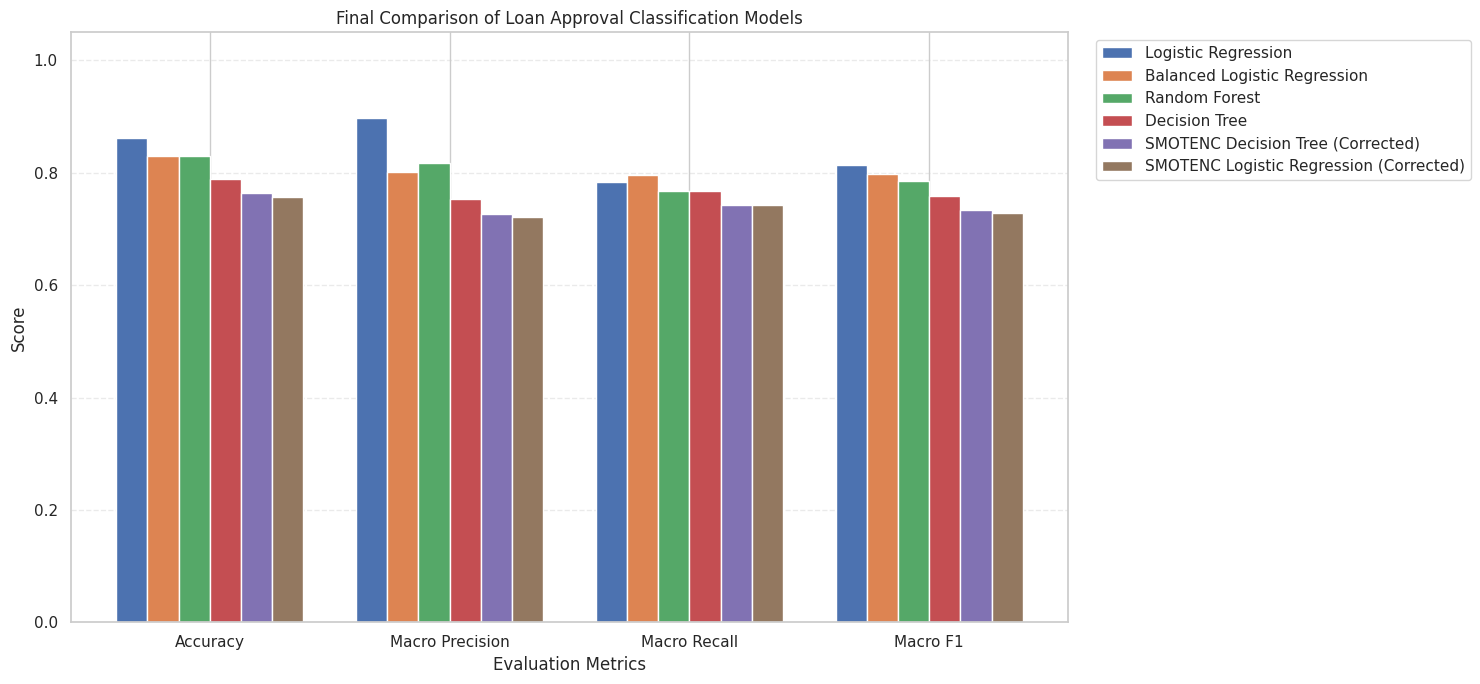

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics to compare
metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

# Prepare chart data
x = np.arange(len(metrics))
width = 0.13

plt.figure(figsize=(15, 7))

for i, (_, row) in enumerate(final_comparison.iterrows()):
    values = [row[metric] for metric in metrics]

    plt.bar(
        x + (i - 2.5) * width,
        values,
        width,
        label=row["Model"]
    )

plt.title("Final Comparison of Loan Approval Classification Models")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

In [49]:
# Save final model comparison table

output_path = "/content/drive/MyDrive/Elevo/Level2/Task4/Final_Model_Comparison.csv"

final_comparison.to_csv(output_path, index=False)

print("Final comparison table saved successfully!")
print("File location:", output_path)

Final comparison table saved successfully!
File location: /content/drive/MyDrive/Elevo/Level2/Task4/Final_Model_Comparison.csv


In [50]:
# Save classification reports for all six models

from sklearn.metrics import classification_report

reports = []

for model_name, predictions in final_models.items():

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    for class_name in ["N", "Y"]:
        reports.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-Score": report[class_name]["f1-score"],
            "Support": report[class_name]["support"]
        })

classification_results = pd.DataFrame(reports)

report_path = "/content/drive/MyDrive/Elevo/Level2/Task4/Classification_Reports.csv"

classification_results.to_csv(report_path, index=False)

print("Classification reports saved successfully!")
print("File location:", report_path)

display(classification_results.head(12))

Classification reports saved successfully!
File location: /content/drive/MyDrive/Elevo/Level2/Task4/Classification_Reports.csv


,Model,Class,Precision,Recall,F1-Score,Support
0,Logistic Regression,N,0.956522,0.578947,0.721311,38.0
1,Logistic Regression,Y,0.840000,0.988235,0.908108,85.0
2,Balanced Logistic Regression,N,0.729730,0.710526,0.720000,38.0
3,Balanced Logistic Regression,Y,0.872093,0.882353,0.877193,85.0
4,Decision Tree,N,0.642857,0.710526,0.675000,38.0
5,Decision Tree,Y,0.864198,0.823529,0.843373,85.0
6,Random Forest,N,0.793103,0.605263,0.686567,38.0
7,Random Forest,Y,0.840426,0.929412,0.882682,85.0
8,SMOTENC Logistic Regression (Corrected),N,0.586957,0.710526,0.642857,38.0
9,SMOTENC Logistic Regression (Corrected),Y,0.857143,0.776471,0.814815,85.0


In [51]:
# Save confusion matrices for all six models

confusion_results = []

for model_name, predictions in final_models.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["N", "Y"]
    )

    confusion_results.append({
        "Model": model_name,
        "True Rejected": cm[0, 0],
        "False Approved": cm[0, 1],
        "False Rejected": cm[1, 0],
        "True Approved": cm[1, 1]
    })

confusion_df = pd.DataFrame(confusion_results)

confusion_path = (
    "/content/drive/MyDrive/Elevo/Level2/Task4/"
    "Confusion_Matrices.csv"
)

confusion_df.to_csv(confusion_path, index=False)

print("Confusion matrices saved successfully!")
print("File location:", confusion_path)

display(confusion_df)

Confusion matrices saved successfully!
File location: /content/drive/MyDrive/Elevo/Level2/Task4/Confusion_Matrices.csv


,Model,True Rejected,False Approved,False Rejected,True Approved
0,Logistic Regression,22,16,1,84
1,Balanced Logistic Regression,27,11,10,75
2,Decision Tree,27,11,15,70
3,Random Forest,23,15,6,79
4,SMOTENC Logistic Regression (Corrected),27,11,19,66
5,SMOTENC Decision Tree (Corrected),26,12,17,68


In [52]:
# Save final model comparison chart

chart_path = (
    "/content/drive/MyDrive/Elevo/Level2/Task4/"
    "Final_Model_Comparison.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

print("Comparison chart saved successfully!")
print("File location:", chart_path)

Comparison chart saved successfully!
File location: /content/drive/MyDrive/Elevo/Level2/Task4/Final_Model_Comparison.png


<Figure size 640x480 with 0 Axes>

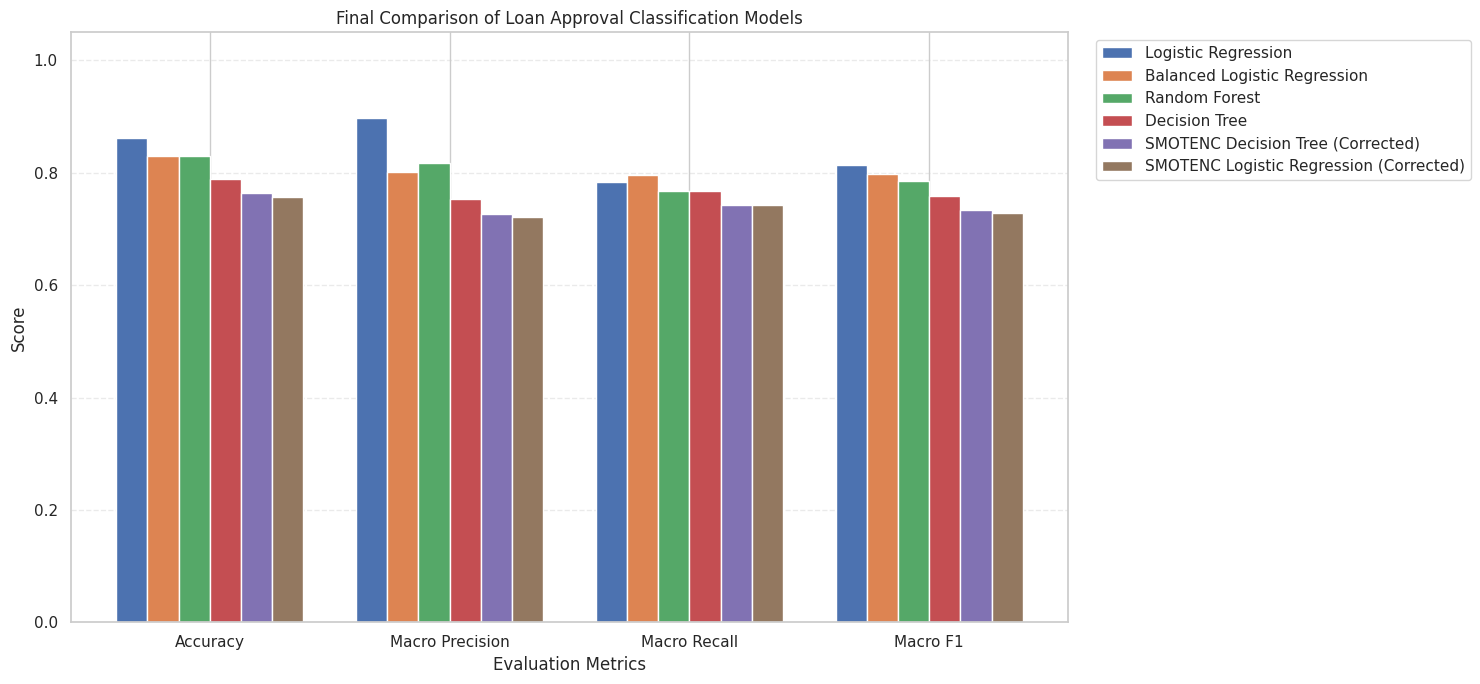

Verified chart saved: /content/drive/MyDrive/Elevo/Level2/Task4/Final_Model_Comparison.png


In [53]:
# Recreate and save the final comparison chart

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

x = np.arange(len(metrics))
width = 0.13

fig, ax = plt.subplots(figsize=(15, 7))

for i, (_, row) in enumerate(final_comparison.iterrows()):
    values = [row[metric] for metric in metrics]

    ax.bar(
        x + (i - 2.5) * width,
        values,
        width,
        label=row["Model"]
    )

ax.set_title("Final Comparison of Loan Approval Classification Models")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()

chart_path = (
    "/content/drive/MyDrive/Elevo/Level2/Task4/"
    "Final_Model_Comparison.png"
)

fig.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Verified chart saved:", chart_path)

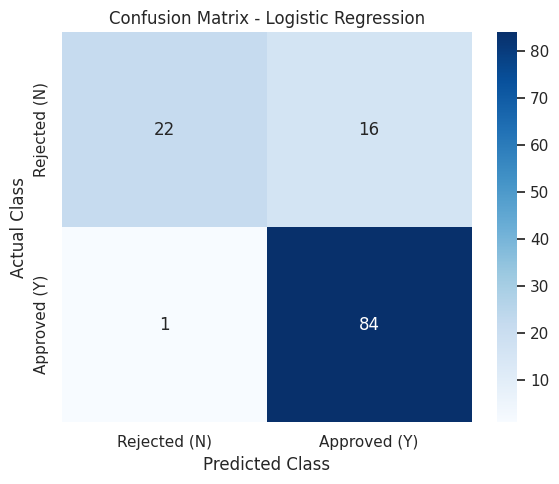

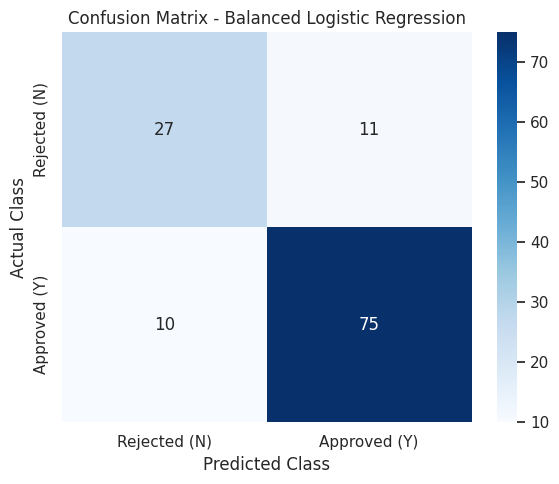

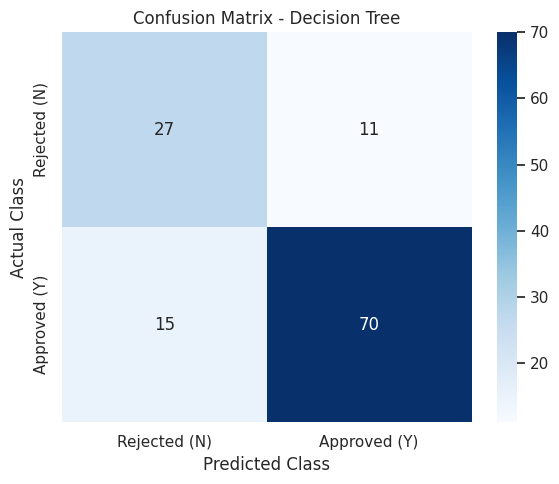

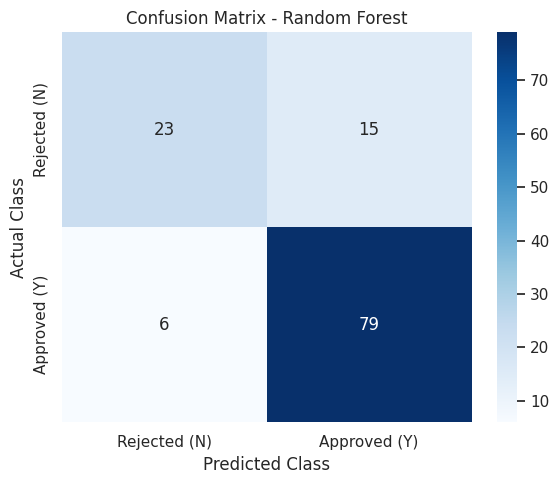

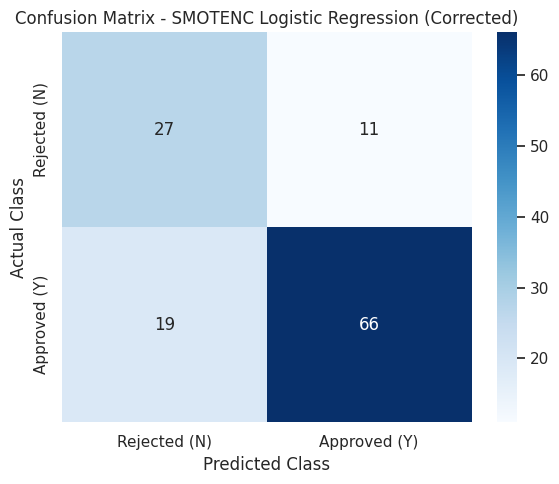

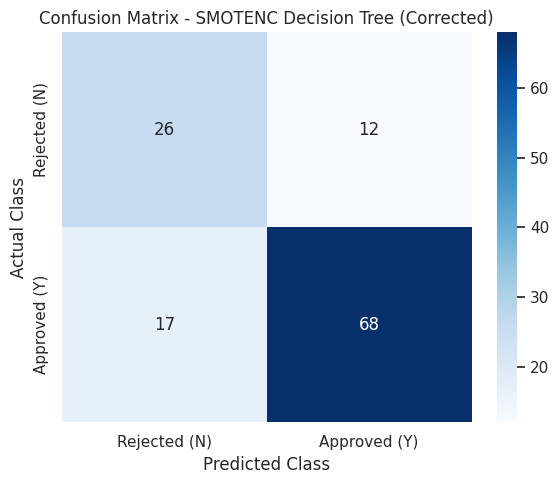

All six confusion matrix heatmaps saved successfully!
Folder: /content/drive/MyDrive/Elevo/Level2/Task4/Confusion_Matrix_Plots


In [54]:
# Generate and save six confusion matrix heatmaps

import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create a folder for the heatmaps
heatmap_folder = (
    "/content/drive/MyDrive/Elevo/Level2/Task4/Confusion_Matrix_Plots"
)

os.makedirs(heatmap_folder, exist_ok=True)

for model_name, predictions in final_models.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["N", "Y"]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Rejected (N)", "Approved (Y)"],
        yticklabels=["Rejected (N)", "Approved (Y)"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()

    # Create a filename from the model name
    filename = model_name.replace(" ", "_").replace("(", "").replace(")", "")
    filename += ".png"

    plt.savefig(
        os.path.join(heatmap_folder, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All six confusion matrix heatmaps saved successfully!")
print("Folder:", heatmap_folder)

In [55]:
# Create README.md for Loan Approval Prediction

readme_content = r"""
# Loan Approval Prediction

## Elevvo Pathways – Machine Learning Track
### Level 2 | Task 4

## 1. Project Overview

This project develops machine learning classification models to predict
whether a loan application will be approved or rejected.

The project explores data preprocessing, exploratory data analysis,
classification algorithms, class imbalance handling and model evaluation.

The primary objective is to build and compare classification models
using appropriate evaluation metrics, particularly Precision, Recall
and F1-score.

## 2. Dataset Description

**Dataset:** Loan Approval Prediction Dataset

**Source:** Loan Prediction Dataset (Kaggle dataset, accessed through
a public GitHub CSV copy).

**Records:** 614 loan applications
**Features:** 11 predictive features
**Target variable:** Loan_Status

Target classes:
- Y: Loan Approved
- N: Loan Rejected

The original dataset contains 13 columns, including Loan_ID and
Loan_Status. Loan_ID was excluded from model training because it is
an identifier rather than a meaningful predictive feature.

## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to understand the
dataset's structure, distributions and relationships.

Activities included:
- Dataset inspection and statistical summaries.
- Missing-value analysis.
- Numerical feature distributions.
- Categorical feature distributions.
- Outlier inspection using boxplots.
- Analysis of loan approval patterns.
- Target class distribution analysis.

### Target Distribution

- Approved (Y): 422 applications (68.73%).
- Rejected (N): 192 applications (31.27%).

The target variable showed moderate class imbalance.

## 4. Data Preprocessing

The following preprocessing activities were performed:

1. Removed the Loan_ID identifier.
2. Separated the predictive features and target variable.
3. Split the dataset into training and testing sets.
4. Used stratified sampling to preserve class proportions.
5. Imputed missing numerical values using the median.
6. Imputed missing categorical values using the most frequent value.
7. Applied StandardScaler to numerical features.
8. Applied One-Hot Encoding to categorical features.

The dataset was split using:
- Training set: 80% (491 records).
- Testing set: 20% (123 records).

The preprocessing transformations were fitted on training data
and applied to test data to prevent data leakage.

## 5. Machine Learning Models

Six model configurations were evaluated:

1. Logistic Regression.
2. Balanced Logistic Regression.
3. Decision Tree.
4. Random Forest.
5. SMOTENC Logistic Regression (corrected encoding).
6. SMOTENC Decision Tree (corrected encoding).

### Handling Class Imbalance

Two approaches were investigated:

**Class Weighting**

The class_weight='balanced' option was used in Logistic Regression
and Decision Tree configurations to give greater consideration
to the minority class.

**SMOTENC**

Synthetic Minority Over-sampling Technique for Nominal and
Continuous features (SMOTENC) was used to balance the training data.

The training distribution changed from:
- Approved (Y): 337
- Rejected (N): 154

To:
- Approved (Y): 337
- Rejected (N): 337

The test set was not resampled.

Ordinal encoding was used to prepare categorical variables for SMOTENC.
After resampling, One-Hot Encoding was applied before training the
corrected SMOTENC classifiers.

## 6. Model Evaluation

The models were evaluated using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Rejected-class Recall
- Classification Reports
- Confusion Matrices

Macro-averaged metrics give equal weight to both target classes,
making them useful when evaluating imbalanced classification data.

### Final Model Comparison

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.8618 | 0.8983 | 0.7836 | 0.8147 |
| Balanced Logistic Regression | 0.8293 | 0.8009 | 0.7964 | 0.7986 |
| Random Forest | 0.8293 | 0.8168 | 0.7673 | 0.7846 |
| Decision Tree | 0.7886 | 0.7535 | 0.7670 | 0.7592 |
| SMOTENC Decision Tree (Corrected) | 0.7642 | 0.7273 | 0.7421 | 0.7331 |
| SMOTENC Logistic Regression (Corrected) | 0.7561 | 0.7220 | 0.7435 | 0.7288 |

## 7. Key Findings

- Logistic Regression achieved the highest overall accuracy of 86.18%.
- Logistic Regression achieved the highest Macro F1-score of 0.8147.
- Balanced Logistic Regression achieved the highest Macro Recall of 0.7964.
- Balanced Logistic Regression and corrected SMOTENC Logistic Regression
  achieved the highest rejected-class recall of 0.7105.
- SMOTENC did not improve overall performance compared with the
  original Logistic Regression.
- Class weighting improved the detection of rejected applications
  compared with the original Logistic Regression.

## 8. Best Performing Model

Based on the Macro F1-score, Logistic Regression was selected as the
best overall model.

Its performance was:

- Accuracy: 86.18%
- Macro Precision: 89.83%
- Macro Recall: 78.36%
- Macro F1-score: 81.47%

However, Balanced Logistic Regression is a useful alternative when
identifying rejected applications is a higher priority.

## 9. Project Limitations

- The dataset contains only 614 observations.
- The dataset may not represent loan applicants across different
  financial institutions or geographical regions.
- The class imbalance techniques did not consistently improve
  overall predictive performance.
- Model performance was evaluated using one stratified train-test split.
- Further validation and hyperparameter tuning may improve
  generalisation.

## 10. Future Improvements

Potential future work includes:

- Cross-validation for more robust performance estimates.
- Hyperparameter optimisation.
- Probability threshold optimisation.
- Evaluation using additional classification algorithms.
- Testing on larger and more diverse loan datasets.
- Model explainability using SHAP or other interpretation methods.
- Deployment as a simple loan prediction application.

## 11. Project Structure

```text
Task4/
│
├── Loan_Approval_Dataset.csv
├── Final_Model_Comparison.csv
├── Classification_Reports.csv
├── Confusion_Matrices.csv
├── Final_Model_Comparison.png
├── Confusion_Matrix_Plots/
└── README.md

_IncompleteInputError: incomplete input (871240084.py, line 3)

In [56]:
# Create README.md for Loan Approval Prediction

readme_content = r"""
# Loan Approval Prediction

## Elevvo Pathways – Machine Learning Track
### Level 2 | Task 4

## 1. Project Overview

This project develops machine learning classification models to predict
whether a loan application will be approved or rejected.

The project explores data preprocessing, exploratory data analysis,
classification algorithms, class imbalance handling and model evaluation.

The primary objective is to build and compare classification models
using appropriate evaluation metrics, particularly Precision, Recall
and F1-score.

## 2. Dataset Description

**Dataset:** Loan Approval Prediction Dataset

**Source:** Loan Prediction Dataset (Kaggle dataset, accessed through
a public GitHub CSV copy).

**Records:** 614 loan applications
**Features:** 11 predictive features
**Target variable:** Loan_Status

Target classes:
- Y: Loan Approved
- N: Loan Rejected

The original dataset contains 13 columns, including Loan_ID and
Loan_Status. Loan_ID was excluded from model training because it is
an identifier rather than a meaningful predictive feature.

## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to understand the
dataset's structure, distributions and relationships.

Activities included:
- Dataset inspection and statistical summaries.
- Missing-value analysis.
- Numerical feature distributions.
- Categorical feature distributions.
- Outlier inspection using boxplots.
- Analysis of loan approval patterns.
- Target class distribution analysis.

### Target Distribution

- Approved (Y): 422 applications (68.73%).
- Rejected (N): 192 applications (31.27%).

The target variable showed moderate class imbalance.

## 4. Data Preprocessing

The following preprocessing activities were performed:

1. Removed the Loan_ID identifier.
2. Separated the predictive features and target variable.
3. Split the dataset into training and testing sets.
4. Used stratified sampling to preserve class proportions.
5. Imputed missing numerical values using the median.
6. Imputed missing categorical values using the most frequent value.
7. Applied StandardScaler to numerical features.
8. Applied One-Hot Encoding to categorical features.

The dataset was split using:
- Training set: 80% (491 records).
- Testing set: 20% (123 records).

The preprocessing transformations were fitted on training data
and applied to test data to prevent data leakage.

## 5. Machine Learning Models

Six model configurations were evaluated:

1. Logistic Regression.
2. Balanced Logistic Regression.
3. Decision Tree.
4. Random Forest.
5. SMOTENC Logistic Regression (corrected encoding).
6. SMOTENC Decision Tree (corrected encoding).

### Handling Class Imbalance

Two approaches were investigated:

**Class Weighting**

The class_weight='balanced' option was used in Logistic Regression
and Decision Tree configurations to give greater consideration
to the minority class.

**SMOTENC**

Synthetic Minority Over-sampling Technique for Nominal and
Continuous features (SMOTENC) was used to balance the training data.

The training distribution changed from:
- Approved (Y): 337
- Rejected (N): 154

To:
- Approved (Y): 337
- Rejected (N): 337

The test set was not resampled.

Ordinal encoding was used to prepare categorical variables for SMOTENC.
After resampling, One-Hot Encoding was applied before training the
corrected SMOTENC classifiers.

## 6. Model Evaluation

The models were evaluated using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Rejected-class Recall
- Classification Reports
- Confusion Matrices

Macro-averaged metrics give equal weight to both target classes,
making them useful when evaluating imbalanced classification data.

### Final Model Comparison

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.8618 | 0.8983 | 0.7836 | 0.8147 |
| Balanced Logistic Regression | 0.8293 | 0.8009 | 0.7964 | 0.7986 |
| Random Forest | 0.8293 | 0.8168 | 0.7673 | 0.7846 |
| Decision Tree | 0.7886 | 0.7535 | 0.7670 | 0.7592 |
| SMOTENC Decision Tree (Corrected) | 0.7642 | 0.7273 | 0.7421 | 0.7331 |
| SMOTENC Logistic Regression (Corrected) | 0.7561 | 0.7220 | 0.7435 | 0.7288 |

## 7. Key Findings

- Logistic Regression achieved the highest overall accuracy of 86.18%.
- Logistic Regression achieved the highest Macro F1-score of 0.8147.
- Balanced Logistic Regression achieved the highest Macro Recall of 0.7964.
- Balanced Logistic Regression and corrected SMOTENC Logistic Regression
  achieved the highest rejected-class recall of 0.7105.
- SMOTENC did not improve overall performance compared with the
  original Logistic Regression.
- Class weighting improved the detection of rejected applications
  compared with the original Logistic Regression.

## 8. Best Performing Model

Based on the Macro F1-score, Logistic Regression was selected as the
best overall model.

Its performance was:

- Accuracy: 86.18%
- Macro Precision: 89.83%
- Macro Recall: 78.36%
- Macro F1-score: 81.47%

However, Balanced Logistic Regression is a useful alternative when
identifying rejected applications is a higher priority.

## 9. Project Limitations

- The dataset contains only 614 observations.
- The dataset may not represent loan applicants across different
  financial institutions or geographical regions.
- The class imbalance techniques did not consistently improve
  overall predictive performance.
- Model performance was evaluated using one stratified train-test split.
- Further validation and hyperparameter tuning may improve
  generalisation.

## 10. Future Improvements

Potential future work includes:

- Cross-validation for more robust performance estimates.
- Hyperparameter optimisation.
- Probability threshold optimisation.
- Evaluation using additional classification algorithms.
- Testing on larger and more diverse loan datasets.
- Model explainability using SHAP or other interpretation methods.
- Deployment as a simple loan prediction application.

## 11. Project Structure

```text
Task4/
│
├── Loan_Approval_Dataset.csv
├── Final_Model_Comparison.csv
├── Classification_Reports.csv
├── Confusion_Matrices.csv
├── Final_Model_Comparison.png
├── Confusion_Matrix_Plots/
└── README.md

_IncompleteInputError: incomplete input (871240084.py, line 3)

In [57]:
from pathlib import Path

readme_content = """# Loan Approval Prediction

## Elevvo Pathways - Machine Learning Track
### Level 2 | Task 4

## 1. Project Overview

This project applies machine learning classification techniques to predict whether a loan application will be approved or rejected.

The objectives are to:
- Explore and understand the loan dataset.
- Clean and preprocess the data.
- Develop classification models.
- Investigate class imbalance handling.
- Compare model performance using appropriate evaluation metrics.

## 2. Dataset Description

Dataset: Loan Approval Prediction Dataset

Source: Kaggle Loan Prediction Dataset, accessed through a public GitHub CSV copy.

- Total records: 614
- Original columns: 13
- Predictive features: 11
- Target variable: Loan_Status

Target classes:
- Y: Loan Approved
- N: Loan Rejected

Loan_ID was excluded from model training because it is an identifier.

## 3. Exploratory Data Analysis

EDA activities included:
- Dataset inspection.
- Missing-value analysis.
- Descriptive statistics.
- Numerical feature distributions.
- Categorical feature distributions.
- Outlier inspection.
- Analysis of relationships between features and loan approval.

Target distribution:
- Approved: 422 (68.73%)
- Rejected: 192 (31.27%)

The dataset exhibits moderate class imbalance.

## 4. Data Preprocessing

The following techniques were applied:
- Removed Loan_ID.
- Separated features and target variable.
- Used an 80:20 stratified train-test split.
- Imputed numerical missing values using the median.
- Imputed categorical missing values using the most frequent value.
- Applied StandardScaler to numerical features.
- Applied One-Hot Encoding to categorical features.

Training records: 491
Testing records: 123

Preprocessing transformations were fitted on training data to prevent data leakage.

## 5. Machine Learning Models

Six model configurations were evaluated:

1. Logistic Regression
2. Balanced Logistic Regression
3. Decision Tree
4. Random Forest
5. Corrected SMOTENC Logistic Regression
6. Corrected SMOTENC Decision Tree

## 6. Handling Class Imbalance

Two approaches were investigated.

### Class Weighting

The class_weight='balanced' option was used to give additional importance to the minority class.

### SMOTENC

SMOTENC was used to generate synthetic minority-class observations while considering both categorical and numerical features.

Training distribution before resampling:
- Approved: 337
- Rejected: 154

Training distribution after resampling:
- Approved: 337
- Rejected: 337

The test set remained unchanged.

After SMOTENC, One-Hot Encoding was applied to categorical features before training the corrected classifiers.

## 7. Model Evaluation

Evaluation metrics included:
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Rejected-class Recall
- Classification Reports
- Confusion Matrices

### Final Model Comparison

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.8618 | 0.8983 | 0.7836 | 0.8147 |
| Balanced Logistic Regression | 0.8293 | 0.8009 | 0.7964 | 0.7986 |
| Random Forest | 0.8293 | 0.8168 | 0.7673 | 0.7846 |
| Decision Tree | 0.7886 | 0.7535 | 0.7670 | 0.7592 |
| SMOTENC Decision Tree | 0.7642 | 0.7273 | 0.7421 | 0.7331 |
| SMOTENC Logistic Regression | 0.7561 | 0.7220 | 0.7435 | 0.7288 |

## 8. Key Findings

- Logistic Regression achieved the highest accuracy of 86.18%.
- Logistic Regression achieved the highest Macro F1-score of 0.8147.
- Balanced Logistic Regression achieved the highest Macro Recall of 0.7964.
- Balanced Logistic Regression and corrected SMOTENC Logistic Regression achieved the highest rejected-class recall of 0.7105.
- SMOTENC did not improve overall performance compared with the original Logistic Regression.
- Class weighting improved minority-class detection compared with the original Logistic Regression.

## 9. Best Performing Model

Logistic Regression was selected as the best overall model based on its Macro F1-score.

Performance:
- Accuracy: 86.18%
- Macro Precision: 89.83%
- Macro Recall: 78.36%
- Macro F1-score: 81.47%

Balanced Logistic Regression is a useful alternative when detecting rejected applications is a higher priority.

## 10. Project Limitations

- The dataset contains only 614 observations.
- The dataset may not represent all financial institutions or geographical regions.
- Imbalance-handling techniques did not consistently improve performance.
- Evaluation used one stratified train-test split.
- Further validation and hyperparameter tuning are recommended.

## 11. Future Improvements

- Apply cross-validation.
- Perform additional hyperparameter optimisation.
- Investigate classification threshold optimisation.
- Explore additional classification algorithms.
- Test on larger and more diverse datasets.
- Investigate model explainability using SHAP.
- Develop a loan prediction application.

## 12. Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Imbalanced-learn
- GitHub

## 13. Conclusion

This project demonstrated the application of machine learning classification techniques to loan approval prediction.

Logistic Regression provided the strongest overall predictive performance, while class weighting improved the identification of rejected applications.

The experiments also demonstrated that addressing class imbalance requires careful evaluation because oversampling does not automatically guarantee improved model performance.

---

Project: Loan Approval Prediction
Programme: Elevvo Pathways - Machine Learning Track
Level: 2
Task: 4
"""

readme_path = Path(
    "/content/drive/MyDrive/Elevo/Level2/Task4/README.md"
)

readme_path.write_text(readme_content, encoding="utf-8")

print("README.md created successfully!")
print("File location:", readme_path)
print("File size:", readme_path.stat().st_size, "bytes")

README.md created successfully!
File location: /content/drive/MyDrive/Elevo/Level2/Task4/README.md
File size: 5628 bytes


In [58]:
# Verify README content

with open(readme_path, "r", encoding="utf-8") as file:
    saved_readme = file.read()

print("README verification")
print("-------------------")
print("File exists:", readme_path.exists())
print("Characters:", len(saved_readme))
print("Contains project overview:", "Project Overview" in saved_readme)
print("Contains model comparison:", "Final Model Comparison" in saved_readme)
print("Contains conclusion:", "Conclusion" in saved_readme)

print("\nFirst 15 lines:")
print("\n".join(saved_readme.splitlines()[:15]))

print("\nLast 10 lines:")
print("\n".join(saved_readme.splitlines()[-10:]))

README verification
-------------------
File exists: True
Characters: 5628
Contains project overview: True
Contains model comparison: True
Contains conclusion: True

First 15 lines:
# Loan Approval Prediction

## Elevvo Pathways - Machine Learning Track
### Level 2 | Task 4

## 1. Project Overview

This project applies machine learning classification techniques to predict whether a loan application will be approved or rejected.

The objectives are to:
- Explore and understand the loan dataset.
- Clean and preprocess the data.
- Develop classification models.
- Investigate class imbalance handling.
- Compare model performance using appropriate evaluation metrics.

Last 10 lines:
Logistic Regression provided the strongest overall predictive performance, while class weighting improved the identification of rejected applications.

The experiments also demonstrated that addressing class imbalance requires careful evaluation because oversampling does not automatically guarantee improved mode

In [59]:
import os

task4_folder = "/content/drive/MyDrive/Elevo/Level2/Task4"

print("TASK 4 PROJECT FILES")
print("====================")

for item in sorted(os.listdir(task4_folder)):
    item_path = os.path.join(task4_folder, item)

    if os.path.isdir(item_path):
        print(f"[FOLDER] {item}")
    else:
        print(f"[FILE]   {item}")

print("\nFolder verification completed!")

TASK 4 PROJECT FILES
[FILE]   Classification_Reports.csv
[FILE]   Confusion_Matrices.csv
[FOLDER] Confusion_Matrix_Plots
[FILE]   Final_Model_Comparison.csv
[FILE]   Final_Model_Comparison.png
[FILE]   Loan_Approval_Dataset.csv
[FILE]   Loan_Approval_Prediction.ipynb
[FILE]   README.md

Folder verification completed!
